In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import os
from malware_pck import featureVector_to_image as img
import importlib
importlib.reload(img)

2026-04-01 16:01:47.920478: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-04-01 16:01:47.969653: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775073707.991430   36674 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775073707.999415   36674 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775073708.041722   36674 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

<module 'malware_pck.featureVector_to_image' from '/home/tdfink/malware_project/src/malware_pck/featureVector_to_image.py'>

In [2]:
saved_indices = img.create_noUnknown_images(200000)
img.show_samples(saved_indices)

Generating exactly 200000 labeled images...


100%|█████████████████████████████████████████████████████████████████████████| 200000/200000 [02:55<00:00, 1137.58it/s]



Generation complete.
Out of the 200000 images generated from X_train:
Total Malware: 100149
Total Benign: 99851
Total Unlabeled: 0


In [3]:
IMG_HEIGHT = 128 
IMG_WIDTH = 128
BATCH_SIZE = 32
data_dir = "../data/images"

In [4]:
print("Loading Training Data:")
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode="grayscale" # Grayscale is perfect for feature vectors
)

Loading Training Data:
Found 200000 files belonging to 2 classes.
Using 160000 files for training.


I0000 00:00:1775073904.942066   36674 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5199 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0


In [5]:
print("Loading Validation Data:")
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode="grayscale"
)

Loading Validation Data:
Found 200000 files belonging to 2 classes.
Using 40000 files for validation.


In [6]:
# Optimize the loading speed for both datasets
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [7]:
print("Defining Baseline Model architecture...")

# Create a Sequential model
baseline_model = models.Sequential([
    # Input layer and feature rescaling (important for stability)
    layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 1)),
    
    # First convolutional block
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(),

    # Transition to dense layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    
    # Output layer for binary classification (Malware vs Benign)
    layers.Dense(1, activation='sigmoid')
])

print("Model architecture defined.")
baseline_model.summary()

Defining Baseline Model architecture...


/home/tdfink/miniforge3/envs/malware_project/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model architecture defined.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,407,681 (32.07 MB)

 Trainable params: 8,407,681 (32.07 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Cell 12
print("Compiling the model...")
baseline_model.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])
print("Model compiled.")

Compiling the model...
Model compiled.


In [9]:
# Updated Cell 13 with Class Weights
EPOCHS = 10

# Define weights: Class 1 (Malware) is 5x more important than Class 0 (Benign)
class_weights = {0: 1.0, 1: 1.5}

print(f"Starting baseline model training with heavy malware weighting...")

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights # <-- Add this parameter here!
)
print("Model training complete.")

Starting baseline model training with heavy malware weighting...
Epoch 1/10


I0000 00:00:1775073927.937272   36805 service.cc:152] XLA service 0x79a3d4008e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775073927.937314   36805 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 5070 Laptop GPU, Compute Capability 12.0
2026-04-01 16:05:27.993859: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1775073928.192433   36805 cuda_dnn.cc:529] Loaded cuDNN version 91002


   9/5000 ━━━━━━━━━━━━━━━━━━━━ 1:06 13ms/step - accuracy: 0.5362 - loss: 1.5615

I0000 00:00:1775073930.145466   36805 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


4070/5000 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8241 - loss: 0.4364

2026-04-01 16:06:27.113232: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:50] could not allocate pinned host memory of size: 8589934592
2026-04-01 16:06:27.113281: W external/local_xla/xla/stream_executor/integrations/stream_executor_allocator.cc:50] could not allocate pinned host memory of size: 7730940928


5000/5000 ━━━━━━━━━━━━━━━━━━━━ 101s 20ms/step - accuracy: 0.8796 - loss: 0.3226 - val_accuracy: 0.9209 - val_loss: 0.1927
Epoch 2/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 68s 13ms/step - accuracy: 0.9238 - loss: 0.2214 - val_accuracy: 0.9323 - val_loss: 0.1675
Epoch 3/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 68s 13ms/step - accuracy: 0.9367 - loss: 0.1872 - val_accuracy: 0.9413 - val_loss: 0.1482
Epoch 4/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 69s 13ms/step - accuracy: 0.9442 - loss: 0.1650 - val_accuracy: 0.9450 - val_loss: 0.1422
Epoch 5/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 70s 14ms/step - accuracy: 0.9502 - loss: 0.1486 - val_accuracy: 0.9483 - val_loss: 0.1371
Epoch 6/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 68s 13ms/step - accuracy: 0.9555 - loss: 0.1343 - val_accuracy: 0.9507 - val_loss: 0.1323
Epoch 7/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 68s 13ms/step - accuracy: 0.9595 - loss: 0.1230 - val_accuracy: 0.9534 - val_loss: 0.1317
Epoch 8/10
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 68s 13ms/step - accuracy: 0.9629 - loss: 0.1

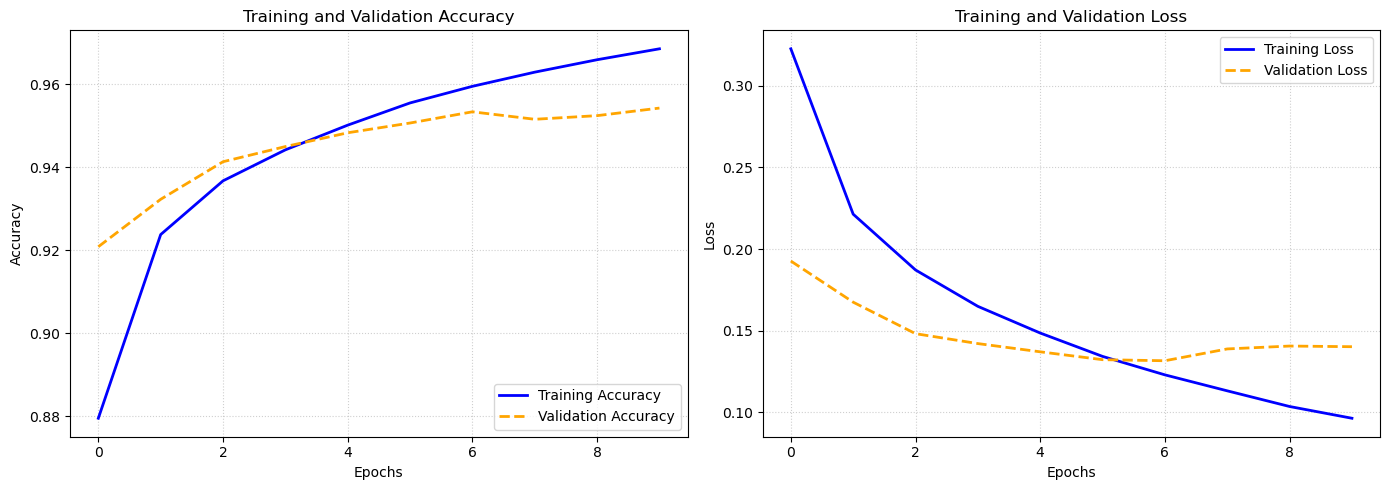

In [10]:
# Extract accuracy and loss metrics from the history object
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

# Set up a wide canvas for two side-by-side plots
plt.figure(figsize=(14, 5))

# 1. Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', linewidth=2)
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', linewidth=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# 2. Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', linewidth=2)
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', linewidth=2, linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Generating predictions on the validation set...
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step


2026-04-01 16:18:20.327737: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



   RESULTS AT THRESHOLD: 0.2
True Negatives (Benign correctly identified):  18546
True Positives (Malware correctly identified): 19427
False Positives (Benign flagged as Malware):   1451  <-- This will go up
False Negatives (Malware missed!):             576  <-- This will go down!


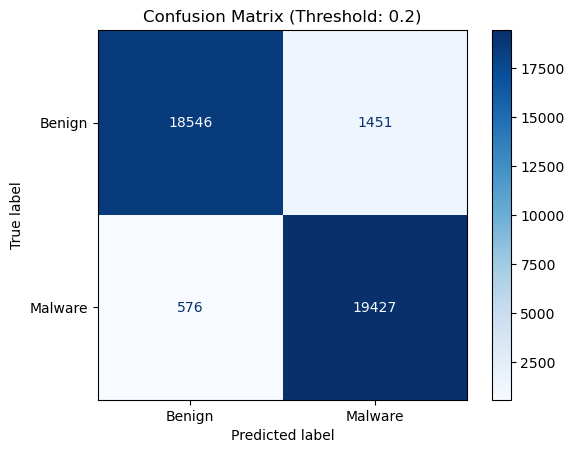

In [12]:
print("Generating predictions on the validation set...")
y_pred_probs = baseline_model.predict(val_ds)

custom_threshold = 0.2
y_pred = (y_pred_probs > custom_threshold).astype(int).flatten()

y_true = []
for _, labels in val_ds:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\n" + "="*45)
print(f"   RESULTS AT THRESHOLD: {custom_threshold}")
print("="*45)
print(f"True Negatives (Benign correctly identified):  {tn}")
print(f"True Positives (Malware correctly identified): {tp}")
print(f"False Positives (Benign flagged as Malware):   {fp}")
print(f"False Negatives (Malware missed!):             {fn}")
print("="*45)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benign', 'Malware'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix (Threshold: {custom_threshold})')
plt.show()